# HomeWork -4
## Objective
 In this homework, you will design a python class that encapsulates common univariate/bivariate analysis tasks. You will practice object oriented programing (OOP) while applying descriptive statistics and visualization to summarize your data and explore the relationship between two variables. 
 
 - Use the example provided in the class activity and expand it. The initializer of the class should take data and print out its shape and column names. 
 - Additionally, your class should include at least 5 methods (function) to do either univariate or bivariate analysis of your choice. 
 - Provide markdowns or comments for each part of your code.  

  - Create an instance of your class using Penguin data and use it to analyze it.
  
  - For each analysis you perform, write 1-2 sentence before that function call that clearly state
    the question you are trying to answer with that analysis. For example: "In this analysis I want to see what is the average mass for each species." 

In [52]:
class BivariateAnalyzer:
    def __init__ (self,data):
        self.df = data.copy()
        print(f'loaded{len(data)} rows, {len(data.columns)} columns')
        print(f'Columns: {list(data.columns)}') # Prints out column names
    
    def quant_quant(self, x, y):
        corr = self.df[[x,y]].corr().iloc[0,1].round(3)
        print(corr)
        plt.figure(figsize = (10,6))
        sns.scatterplot(self.df, x = x, y = y)
        plt.title(f'{x} vs {y}')
        plt.show()
        return corr

    def cat_quant(self, cat, quant, hue = None):
        plt.figure(figsize = (10,6))
        sns.boxplot(data = self.df, x = cat, y = quant, hue = hue)
        plt.title(f'{cat} vs {quant}')
        plt.xticks(rotation = 45)
        plt.show()
        means = self.df.groupby(cat)[quant].mean().round(1)
        print(f'Means by {cat}:')
        print(means)
        return means

    def cat_cat(self, cat1, cat2):
        plt.figure(figsize = (10,6)) # Changes plot size
        sns.countplot(data = self.df, x = cat1, hue = cat2) # Creates a count plot
        plt.title(f'{cat1} vs {cat2}') # Create title with both cat variables
        plt.show() # Shows plot
        
    def uni_hist(self, column):
        plt.figure(figsize = (10,6)) # Changes plot size
        sns.histplot(data = self.df, x = column, kde = True) # Create the histogram with a smooth line 
        plt.title(f'Distribution of {column}') # Create a title
        plt.show() # Shows plot

    def summary_table(self, column):
        summary = self.df[column].describe() #assigns summary to a column description
        return summary # Returns the summary

In [53]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [54]:
penguins = sns.load_dataset('penguins')
df = BivariateAnalyzer(penguins)

loaded344 rows, 7 columns
Columns: ['species', 'island', 'bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g', 'sex']


# Is there a relationship between bill length and bill depth?

-0.235


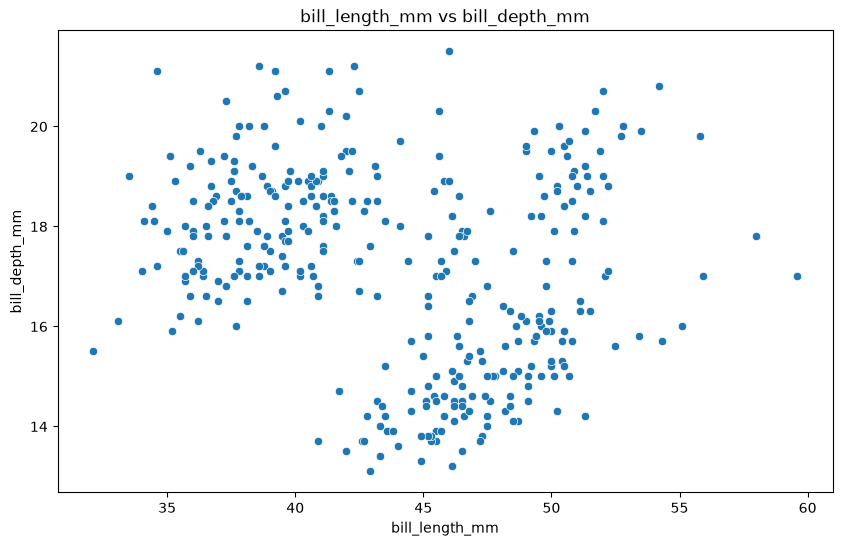

np.float64(-0.235)

In [55]:
df.quant_quant("bill_length_mm", "bill_depth_mm")

# Comparing body mass across different penguin species.

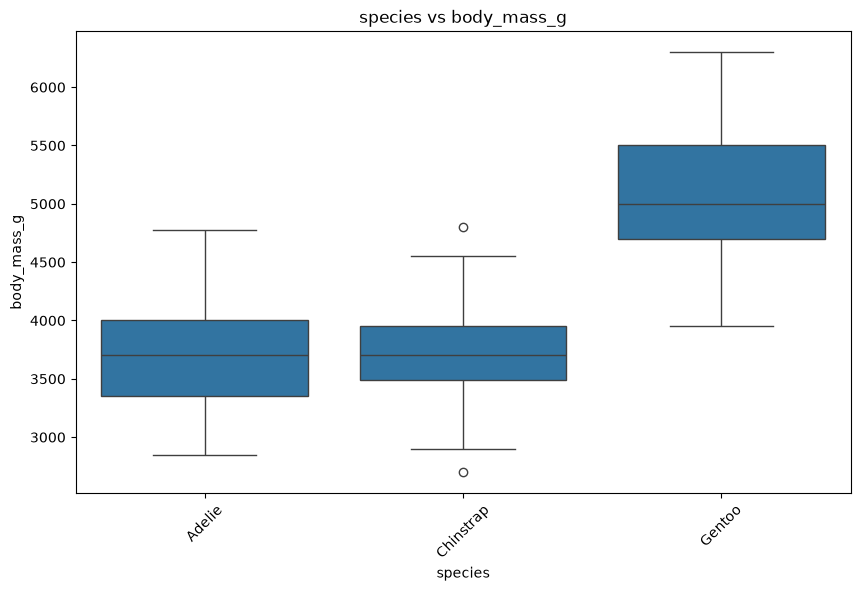

Means by species:
species
Adelie       3700.7
Chinstrap    3733.1
Gentoo       5076.0
Name: body_mass_g, dtype: float64


species
Adelie       3700.7
Chinstrap    3733.1
Gentoo       5076.0
Name: body_mass_g, dtype: float64

In [56]:
df.cat_quant("species", "body_mass_g")

# How are species distributed across islands?

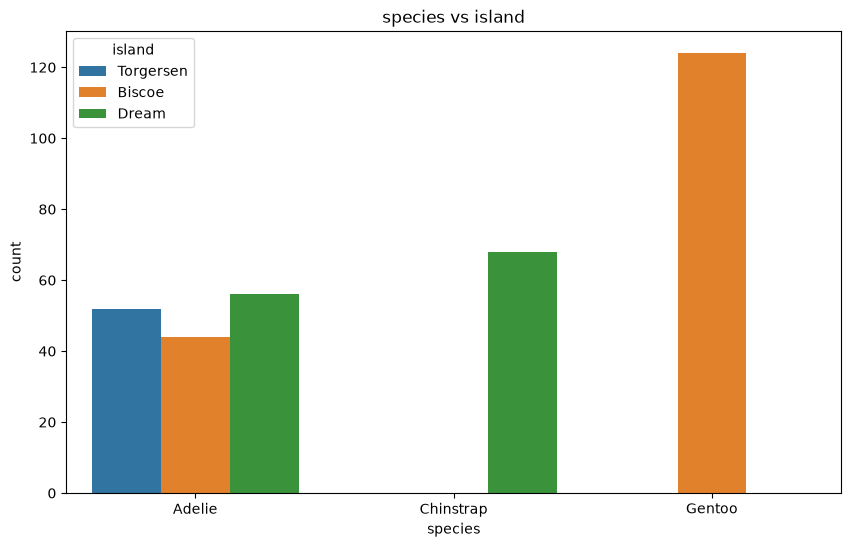

In [57]:
df.cat_cat("species", "island")

# What's the ditribution of body mass?

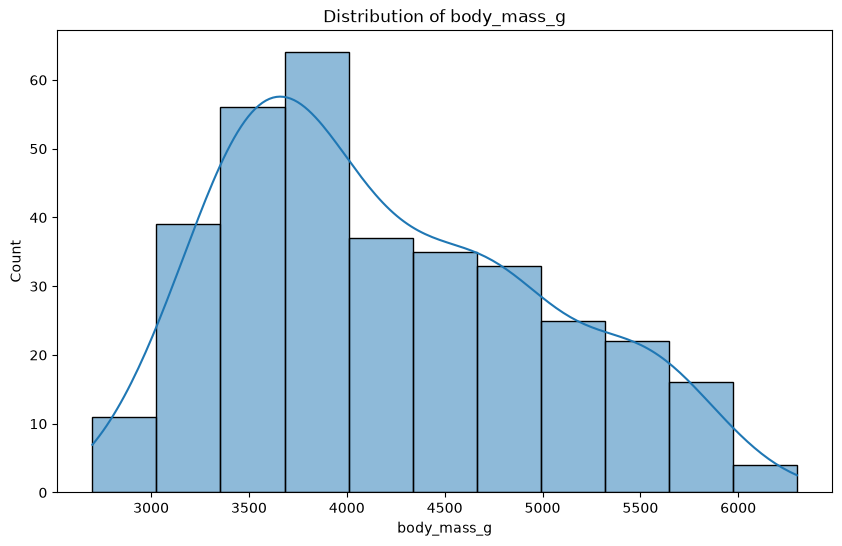

In [58]:
df.uni_hist("body_mass_g")

# What are the summary statistics for body mass?

In [59]:
df.summary_table("body_mass_g")

count     342.000000
mean     4201.754386
std       801.954536
min      2700.000000
25%      3550.000000
50%      4050.000000
75%      4750.000000
max      6300.000000
Name: body_mass_g, dtype: float64